# M2 - Création de la cible `price_category`

Objectif : classer chaque logement selon son prix **relatif à des logements comparables** (et non au prix global).

Entrée : `Data_cleaning/data/processed/house_clean.csv` (jeu nettoyé de M1).

Sorties, toutes dans le dossier `Target_creation/` :
- `data/labeled/house_labeled.csv` : variables d'origine + `price_category`, sans colonnes auxiliaires
- `data/labeled/target_helpers.csv` : colonnes auxiliaires, à ne JAMAIS donner au modèle
- `data/labeled/target_definition.md` : documentation de la cible pour M3, M4 et le rapport
- `data/labeled/feature_options.json` : valeurs et plages pour M3 et M6
- `data/labeled/example_houses.csv` et `example_houses_explained.csv` : exemples pour la démonstration
- `docs/figures/target/m2_ratio_distribution.png` et `m2_class_distribution.png` : figures pour le rapport

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme()

In [2]:
# ---- CONFIGURATION ----
# Le notebook retrouve tout seul la racine du dépôt (le dossier qui contient `Target_creation/`),
# qu'il soit lancé depuis Target_creation/notebooks/ ou depuis la racine du dépôt.
def find_project_root(start=None):
    here = (start or Path.cwd()).resolve()
    for folder in [here, *here.parents]:
        if (folder / "Target_creation").is_dir():
            return folder
    raise FileNotFoundError(
        "Racine du dépôt introuvable : lancez le notebook depuis le dépôt "
        "(dossier contenant Target_creation/)."
    )

ROOT = find_project_root()

# Jeu nettoyé de M1 : le premier chemin qui existe est utilisé
CSV_CANDIDATES = [
    ROOT / "Data_cleaning" / "data" / "processed" / "house_clean.csv",   # emplacement officiel (module M1)
    ROOT / "data" / "processed" / "house_clean.csv",
    ROOT / "data" / "clean" / "house_clean.csv",
]
DATA_PATH = next((p for p in CSV_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "house_clean.csv introuvable. Chemins cherchés :\n" + "\n".join(f"  - {p}" for p in CSV_CANDIDATES)
    )
print("CSV utilisé :", DATA_PATH.relative_to(ROOT))

MODULE_DIR = ROOT / "Target_creation"
OUT_DIR = MODULE_DIR / "data" / "labeled"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = MODULE_DIR / "docs" / "figures" / "target"
FIG_DIR.mkdir(parents=True, exist_ok=True)

PRICE_COL = "price"          # prix demandé
AREA_COL = "sqft_living"     # surface habitable en pieds carrés
ZONE_COL = "zipcode"         # code postal (70 zones)
BEDROOMS_COL = "bedrooms"    # utilisé seulement si USE_BEDROOMS = True
CATEGORICAL_OVERRIDES = ["zipcode"]  # numérique dans le CSV mais à traiter comme catégorie

USE_BEDROOMS = False
N_SIZE_BUCKETS = 3  # 3 tranches : seulement ~1 % des maisons tombent dans un groupe < 30 (4 tranches : ~4 %)
MIN_GROUP_SIZE = 30

# Seuils de départ : à vérifier et justifier avec la distribution réelle du ratio
THRESHOLDS = [0.85, 1.15, 1.40]
LABELS = {0: "Cheaper than average", 1: "Reasonable price", 2: "Over priced", 3: "Too over priced"}

CSV utilisé : Data_cleaning/data/processed/house_clean.csv


In [3]:
df = pd.read_csv(DATA_PATH, dtype={"zipcode": str})  # zipcode = identifiant, pas un nombre (comme le fait M1)
print(df.shape)
display(df.head())

needed = [PRICE_COL, AREA_COL, ZONE_COL] + ([BEDROOMS_COL] if USE_BEDROOMS else [])
missing = [c for c in needed if c not in df.columns]
assert not missing, f"Colonnes introuvables : {missing}"

print("Prix <= 0 :", (df[PRICE_COL] <= 0).sum())
print("Surface <= 0 :", (df[AREA_COL] <= 0).sum())
print("Valeurs manquantes (colonnes utilisées) :")
print(df[needed].isna().sum())
# Signalements pour M1 / M3 (aucune ligne n'est supprimée ni modifiée)
print("Lignes dupliquées :", int(df.duplicated().sum()))
print("Logements à 0 chambre :", int((df["bedrooms"] == 0).sum()), "| à 0 salle de bain :", int((df["bathrooms"] == 0).sum()))

(21428, 15)


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,zipcode,renovated
0,1310000.0,4,2.25,3750,5000,2.0,0,0,5,8,2440,1310,1924,98115,0
1,445500.0,2,1.75,1390,6670,1.0,0,0,3,6,720,670,1941,98115,0
2,450000.0,5,2.00,1870,7344,1.5,0,0,3,7,1870,0,1960,98007,0
3,359000.0,2,2.75,1370,1140,2.0,0,0,3,8,1080,290,2009,98133,0
4,1695000.0,5,3.00,3320,5354,2.0,0,0,3,9,3320,0,2004,98103,0


Prix <= 0 : 0
Surface <= 0 : 0
Valeurs manquantes (colonnes utilisées) :
price          0
sqft_living    0
zipcode        0
dtype: int64
Lignes dupliquées : 5
Logements à 0 chambre : 6 | à 0 salle de bain : 3


## 1. Prix au pied carré et tranches de surface

In [4]:
work = df.copy()
work["price_per_sqft"] = work[PRICE_COL] / work[AREA_COL]
work["size_bucket"] = pd.qcut(work[AREA_COL], q=N_SIZE_BUCKETS, labels=False, duplicates="drop")

print(work.groupby("size_bucket")[AREA_COL].agg(["min", "max", "count"]))

              min    max  count
size_bucket                    
0             370   1584   7144
1            1590   2310   7186
2            2311  13540   7098


## 2. Groupes de comparaison (peer groups) avec repli si le groupe est trop petit

Niveaux : fin (zone + tranche de surface [+ chambres]) -> moyen (zone + tranche) -> large (zone) -> global.
On prend le premier niveau qui contient au moins `MIN_GROUP_SIZE` logements.

In [5]:
keys_fine = [ZONE_COL, "size_bucket"] + ([BEDROOMS_COL] if USE_BEDROOMS else [])
keys_mid = [ZONE_COL, "size_bucket"]
keys_coarse = [ZONE_COL]

def group_stats(frame, keys):
    g = frame.groupby(keys)["price_per_sqft"]
    return g.transform("median"), g.transform("size")

med_f, n_f = group_stats(work, keys_fine)
med_m, n_m = group_stats(work, keys_mid)
med_c, n_c = group_stats(work, keys_coarse)
global_median = work["price_per_sqft"].median()

ok_f, ok_m, ok_c = n_f >= MIN_GROUP_SIZE, n_m >= MIN_GROUP_SIZE, n_c >= MIN_GROUP_SIZE

work["peer_median"] = np.where(ok_f, med_f, np.where(ok_m, med_m, np.where(ok_c, med_c, global_median)))
work["peer_level"] = np.select([ok_f, ok_m, ok_c], ["fine", "mid", "coarse"], default="global")

print(work["peer_level"].value_counts(normalize=True).round(3))
print("Taille des groupes fins :")
print(n_f.describe())

small_groups = work[~ok_f].groupby(keys_fine).ngroups
print(f"Groupes fins < {MIN_GROUP_SIZE} maisons : {small_groups} groupes, {(~ok_f).sum()} maisons ({(~ok_f).mean():.1%}) -> repli sur la médiane du code postal")
print("Repli global nécessaire :", int((work["peer_level"] == "global").sum()), "maisons")

peer_level
fine      0.988
coarse    0.012
Name: proportion, dtype: float64
Taille des groupes fins :
count    21428.000000
mean       145.147097
std         74.975777
min          3.000000
25%         84.000000
50%        135.000000
75%        197.000000
max        343.000000
Name: price_per_sqft, dtype: float64
Groupes fins < 30 maisons : 15 groupes, 254 maisons (1.2%) -> repli sur la médiane du code postal
Repli global nécessaire : 0 maisons


## 3. Ratio de prix et choix des seuils

count    21428.000000
mean         1.032022
std          0.257101
min          0.255976
5%           0.707032
10%          0.776117
25%          0.885199
50%          1.000000
75%          1.128613
90%          1.303698
95%          1.456289
max          4.236786
Name: ratio, dtype: float64


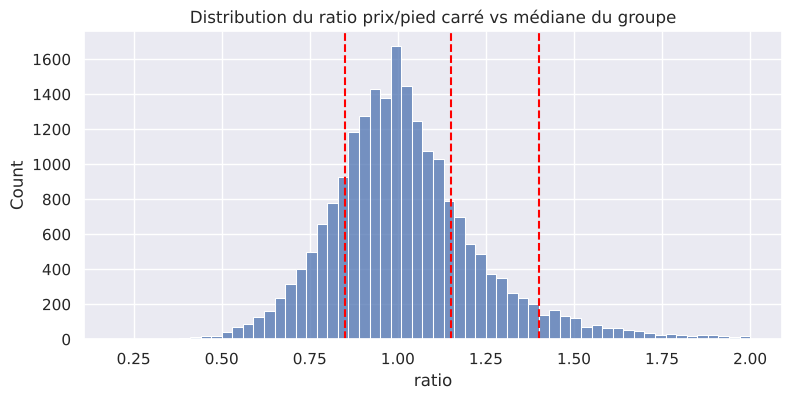

In [6]:
work["ratio"] = work["price_per_sqft"] / work["peer_median"]
print(work["ratio"].describe(percentiles=[.05, .10, .25, .50, .75, .90, .95]))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(work["ratio"], bins=60, binrange=(0.2, 2.0), ax=ax)
for t in THRESHOLDS:
    ax.axvline(t, color="red", linestyle="--")
ax.set_title("Distribution du ratio prix/pied carré vs médiane du groupe")
fig.savefig(FIG_DIR / "m2_ratio_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Création des 4 classes et équilibre

                    n     %                 label
price_category                                   
0                4076  19.0  Cheaper than average
1               12559  58.6      Reasonable price
2                3426  16.0           Over priced
3                1367   6.4       Too over priced


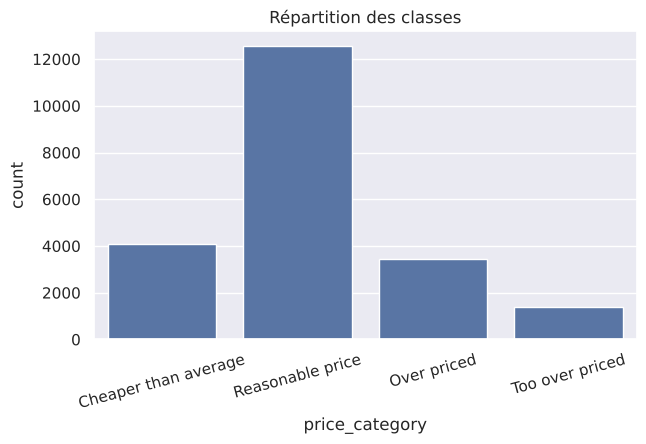

In [7]:
work["price_category"] = np.digitize(work["ratio"], THRESHOLDS)  # 0, 1, 2, 3

counts = work["price_category"].value_counts().sort_index()
print(pd.DataFrame({"n": counts, "%": (counts / len(work) * 100).round(1),
                    "label": [LABELS[i] for i in counts.index]}))

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(x=work["price_category"].map(LABELS),
              order=[LABELS[i] for i in sorted(LABELS)], ax=ax)
ax.set_title("Répartition des classes")
ax.tick_params(axis="x", rotation=15)
fig.savefig(FIG_DIR / "m2_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Tests de cohérence

In [8]:
def category_for(price, area, peer_median):
    ratio = (price / area) / peer_median
    return ratio, int(np.digitize(ratio, THRESHOLDS))

row = work.iloc[0]
print(f"Logement de référence : ratio actuel = {row['ratio']:.2f}, classe {int(row['price_category'])}")

print("Test 1 : même logement, seul le prix demandé change")
classes_t1 = []
for factor in [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]:
    r, c = category_for(row[PRICE_COL] * factor, row[AREA_COL], row["peer_median"])
    classes_t1.append(c)
    print(f"  prix x{factor:<4} -> ratio {r:.2f} -> classe {c} ({LABELS[c]})")
assert classes_t1 == sorted(classes_t1), "La classe ne doit jamais baisser quand le prix augmente"
assert classes_t1[0] < classes_t1[-1], "La classe doit pouvoir changer quand seul le prix change"

print("Test 2 : même prix, surfaces différentes (médiane du groupe supposée fixe)")
classes_t2 = []
for factor in [0.7, 1.0, 1.3, 1.6]:
    r, c = category_for(row[PRICE_COL], row[AREA_COL] * factor, row["peer_median"])
    classes_t2.append(c)
    print(f"  surface x{factor:<4} -> ratio {r:.2f} -> classe {c} ({LABELS[c]})")
assert classes_t2 == sorted(classes_t2, reverse=True), "À prix égal, une plus grande surface ne doit jamais donner une classe plus chère"
print("Tests de cohérence réussis")

Logement de référence : ratio actuel = 1.14, classe 1
Test 1 : même logement, seul le prix demandé change
  prix x0.6  -> ratio 0.69 -> classe 0 (Cheaper than average)
  prix x0.8  -> ratio 0.91 -> classe 1 (Reasonable price)
  prix x1.0  -> ratio 1.14 -> classe 1 (Reasonable price)
  prix x1.2  -> ratio 1.37 -> classe 2 (Over priced)
  prix x1.5  -> ratio 1.72 -> classe 3 (Too over priced)
  prix x2.0  -> ratio 2.29 -> classe 3 (Too over priced)
Test 2 : même prix, surfaces différentes (médiane du groupe supposée fixe)
  surface x0.7  -> ratio 1.63 -> classe 3 (Too over priced)
  surface x1.0  -> ratio 1.14 -> classe 1 (Reasonable price)
  surface x1.3  -> ratio 0.88 -> classe 1 (Reasonable price)
  surface x1.6  -> ratio 0.71 -> classe 0 (Cheaper than average)
Tests de cohérence réussis


**Interprétation des tests**
- Test 1 : quand seul le prix demandé augmente, le ratio augmente proportionnellement et la classe monte (ou reste égale), jamais l'inverse. La classe peut donc bien changer avec le prix seul, ce qui est le comportement voulu.
- Test 2 : à prix égal, une surface plus petite donne un prix au pied carré plus élevé, donc une classe plus chère ; une surface plus grande donne une classe moins chère ou égale. Une grande surface ne fait pas forcément descendre d'une classe : le ratio doit franchir un seuil.
- Limite : ce test garde la médiane du groupe fixe. Dans la réalité, changer la surface peut changer de tranche de surface, donc de groupe de comparaison. Le test vérifie le sens de la règle, il ne simule pas une prédiction du modèle.

## 6. Sauvegarde : jeu étiqueté + colonnes auxiliaires séparées

In [9]:
HELPER_COLS = ["price_per_sqft", "size_bucket", "peer_median", "peer_level", "ratio"]

labeled = df.copy()
labeled["price_category"] = work["price_category"].values
assert not set(HELPER_COLS) & set(labeled.columns), "Une colonne auxiliaire a fuité dans le jeu étiqueté"

labeled.to_csv(OUT_DIR / "house_labeled.csv", index=False)
work[HELPER_COLS + ["price_category"]].to_csv(OUT_DIR / "target_helpers.csv", index_label="row_id")
print(labeled.shape, "->", OUT_DIR / "house_labeled.csv")

(21428, 16) -> /tmp/claude-0/-home-claude/1e679c4c-429e-53e2-a3d6-b143ed5bc3f2/scratchpad/build/Target_creation/data/labeled/house_labeled.csv


## 7. Valeurs et plages pour M3 et M6

In [10]:
features = labeled.drop(columns=["price_category"])
num_cols = [c for c in features.select_dtypes(include="number").columns if c not in CATEGORICAL_OVERRIDES]
cat_cols = [c for c in features.columns if c not in num_cols]

options = {
    "numerical": {c: {"min": float(features[c].min()),
                      "max": float(features[c].max()),
                      "median": float(features[c].median())} for c in num_cols},
    "categorical": {c: sorted(features[c].dropna().astype(str).unique().tolist()) for c in cat_cols},
    "labels": {str(k): v for k, v in LABELS.items()},
    "excluded_helper_columns": HELPER_COLS,
    "dtypes": {c: "str" for c in cat_cols},
}
with open(OUT_DIR / "feature_options.json", "w", encoding="utf-8") as f:
    json.dump(options, f, indent=2, ensure_ascii=False)
print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)

Numériques : ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'renovated']
Catégorielles : ['zipcode']


## 8. Exemples de logements pour la démonstration

In [11]:
# Choix déterministe : logements typiques (surface et prix dans la zone centrale),
# proches du ratio médian de leur classe, et de codes postaux différents
central = (work[AREA_COL].between(work[AREA_COL].quantile(0.25), work[AREA_COL].quantile(0.75))
           & work[PRICE_COL].between(work[PRICE_COL].quantile(0.10), work[PRICE_COL].quantile(0.90))
           & (work["peer_level"] == "fine"))
ex_idx = []
for k in sorted(LABELS):
    in_class = work["price_category"] == k
    pool = work[in_class & central]
    if len(pool) < 2:
        pool = work[in_class]
    class_median = work.loc[in_class, "ratio"].median()
    pool = pool.assign(gap=(pool["ratio"] - class_median).abs()).sort_values("gap")
    zones = set()
    for idx, r in pool.iterrows():
        if r[ZONE_COL] in zones:
            continue
        ex_idx.append(idx)
        zones.add(r[ZONE_COL])
        if len(zones) == 2:
            break

examples = labeled.loc[ex_idx]
examples.to_csv(OUT_DIR / "example_houses.csv", index=False)
explained = work.loc[ex_idx, [PRICE_COL, AREA_COL, ZONE_COL] + HELPER_COLS + ["price_category"]]
explained.to_csv(OUT_DIR / "example_houses_explained.csv", index_label="row_id")
display(explained.round(2))

,price,sqft_living,zipcode,price_per_sqft,size_bucket,peer_median,peer_level,ratio,price_category
7863,290500.0,2510,98055,115.74,2,150.05,fine,0.77,0
19157,398000.0,1720,98136,231.40,1,300.04,fine,0.77,0
1447,645000.0,2250,98006,286.67,1,288.21,fine,0.99,1
3369,600000.0,1520,98115,394.74,0,396.84,fine,0.99,1
6259,509990.0,1440,98118,354.16,0,287.41,fine,1.23,2
5411,856000.0,1480,98112,578.38,0,469.27,fine,1.23,2
18417,520000.0,1940,98038,268.04,1,171.08,fine,1.57,3
19562,689800.0,2390,98133,288.62,2,184.38,fine,1.57,3


## 9. Justification des seuils et sensibilité

In [12]:
pcts = [(work["ratio"] < t).mean() * 100 for t in THRESHOLDS]
q = work["ratio"].quantile([0.25, 0.75])
print("Percentile de chaque seuil :", [f"{t} -> {p:.1f} %" for t, p in zip(THRESHOLDS, pcts)])
print(f"Moitié centrale des ratios : de {q[0.25]:.3f} à {q[0.75]:.3f}")

alternatives = [THRESHOLDS, [0.80, 1.20, 1.50], [0.85, 1.15, 1.30], [0.90, 1.10, 1.30]]
sens_lines = []
for alt in alternatives:
    dist = pd.Series(np.digitize(work["ratio"], alt)).value_counts(normalize=True).sort_index() * 100
    line = f"- {alt} : " + " / ".join(f"{v:.1f} %" for v in dist.values)
    sens_lines.append(line)
    print(line)

Percentile de chaque seuil : ['0.85 -> 19.0 %', '1.15 -> 77.6 %', '1.4 -> 93.6 %']
Moitié centrale des ratios : de 0.885 à 1.129
- [0.85, 1.15, 1.4] : 19.0 % / 58.6 % / 16.0 % / 6.4 %
- [0.8, 1.2, 1.5] : 12.5 % / 70.6 % / 12.8 % / 4.1 %
- [0.85, 1.15, 1.3] : 19.0 % / 58.6 % / 12.2 % / 10.2 %
- [0.9, 1.1, 1.3] : 27.9 % / 42.6 % / 19.4 % / 10.2 %


**Pourquoi ces seuils (0,85 / 1,15 / 1,40)**
- Un prix « raisonnable » est défini comme un écart d'au plus 15 % par rapport à la médiane de logements comparables : règle simple à expliquer et à défendre. La moitié centrale des ratios se situe déjà entre environ 0,89 et 1,13, donc la bande de plus ou moins 15 % couvre un peu plus que le cœur de la distribution.
- Le seuil 1,40 sépare « trop cher » de « beaucoup trop cher » : il isole environ les 6 % de logements les plus chers par rapport à leurs semblables, ce qui laisse plus de 1 000 exemples à la classe 3, assez pour que le modèle puisse l'apprendre.
- Ces seuils restent un choix de conception, pas une vérité mesurée. Le tableau de sensibilité ci-dessus montre comment la répartition change avec d'autres seuils ; M4 peut vérifier que ses conclusions tiennent avec une variante.

## 9 bis. Contrôle indicatif : d'où vient le signal ?

Le modèle reçoit `price`, `sqft_living` et `zipcode`, qui servent aussi à construire la cible. Pour mesurer cette dépendance, on entraîne un arbre simple (profondeur 12, même découpage 80/20 stratifié que le projet) avec puis sans la colonne `price`. Ce n'est **pas** le modèle final (travail de M4) : c'est un contrôle de cohérence de la cible.

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_all = labeled.drop(columns=["price_category"]).copy()
X_all[ZONE_COL] = X_all[ZONE_COL].astype(int)   # codage simple, suffisant pour ce contrôle
y_all = labeled["price_category"]
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)

def score(model, cols):
    pred = model.fit(X_tr[cols], y_tr).predict(X_te[cols])
    return accuracy_score(y_te, pred), f1_score(y_te, pred, average="macro")

all_cols = list(X_all.columns)
no_price = [c for c in all_cols if c != PRICE_COL]
rows = {
    "Zero-R (classe majoritaire)": score(DummyClassifier(strategy="most_frequent"), all_cols),
    "Arbre, toutes variables (avec price)": score(DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE), all_cols),
    "Arbre, sans la colonne price": score(DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE), no_price),
}
check = pd.DataFrame(rows, index=["Exactitude", "F1 macro"]).T.round(3)
display(check)
check.to_csv(OUT_DIR / "price_dependency_check.csv", index_label="modele")

,Exactitude,F1 macro
Zero-R (classe majoritaire),0.586,0.185
"Arbre, toutes variables (avec price)",0.669,0.543
"Arbre, sans la colonne price",0.588,0.398


## 10. Documentation de la cible (remise à M3 et M4)

In [14]:
report = [
    "# Définition de la cible `price_category`",
    "",
    f"- Jeu de données : {len(df)} logements.",
    f"- Prix comparable : prix au pied carré = `{PRICE_COL}` / `{AREA_COL}`.",
    f"- Groupes de comparaison : `{ZONE_COL}` x {N_SIZE_BUCKETS} tranches de `{AREA_COL}` (repli sur `{ZONE_COL}` puis médiane globale si groupe < {MIN_GROUP_SIZE}).",
    "- Ratio = prix au pied carré du logement / médiane de son groupe.",
    f"- Seuils du ratio : {THRESHOLDS}",
    "",
    "## Classes",
]
for k in sorted(LABELS):
    n_k = int(counts.get(k, 0))
    report.append(f"- {k} - {LABELS[k]} : {n_k} logements ({n_k / len(work) * 100:.1f} %)")
report += [
    "",
    "## Justification des seuils",
    "- Bande de plus ou moins 15 % autour de la médiane du groupe = prix raisonnable.",
    "- " + ", ".join(f"seuil {t} = percentile {p:.1f}" for t, p in zip(THRESHOLDS, pcts)),
    "- Sensibilité (répartition des 4 classes selon d'autres seuils) :",
] + ["  " + l for l in sens_lines]
report += [
    "",
    "## Colonnes à exclure des variables d'entrée du modèle",
    "- " + ", ".join(HELPER_COLS) + " (voir `target_helpers.csv`)",
    "- `price_category` est la cible (y).",
    "",
    "## Chargement : attention à zipcode",
    "`zipcode` est un identifiant, pas un nombre. Charger le fichier avec :",
    "    df = pd.read_csv('house_labeled.csv', dtype={'zipcode': str})",
    "puis l'encoder en one-hot (ne pas le mettre à l'échelle comme une variable numérique).",
    "",
    "## Remarque",
    f"Le modèle reçoit `{PRICE_COL}`, `{AREA_COL}` et `{ZONE_COL}`, qui servent aussi à construire la cible : un score élevé reflète en partie la règle de construction.",
]
(OUT_DIR / "target_definition.md").write_text(chr(10).join(report), encoding="utf-8")
print(chr(10).join(report))

# Définition de la cible `price_category`

- Jeu de données : 21428 logements.
- Prix comparable : prix au pied carré = `price` / `sqft_living`.
- Groupes de comparaison : `zipcode` x 3 tranches de `sqft_living` (repli sur `zipcode` puis médiane globale si groupe < 30).
- Ratio = prix au pied carré du logement / médiane de son groupe.
- Seuils du ratio : [0.85, 1.15, 1.4]

## Classes
- 0 - Cheaper than average : 4076 logements (19.0 %)
- 1 - Reasonable price : 12559 logements (58.6 %)
- 2 - Over priced : 3426 logements (16.0 %)
- 3 - Too over priced : 1367 logements (6.4 %)

## Justification des seuils
- Bande de plus ou moins 15 % autour de la médiane du groupe = prix raisonnable.
- seuil 0.85 = percentile 19.0, seuil 1.15 = percentile 77.6, seuil 1.4 = percentile 93.6
- Sensibilité (répartition des 4 classes selon d'autres seuils) :
  - [0.85, 1.15, 1.4] : 19.0 % / 58.6 % / 16.0 % / 6.4 %
  - [0.8, 1.2, 1.5] : 12.5 % / 70.6 % / 12.8 % / 4.1 %
  - [0.85, 1.15, 1.3] : 19.0 % / 58.6 % /